Publication adaptation: workspace labels and runtime paths have been renamed. Saved scientific results and embedded image bytes are retained from the recorded run; this source notebook has not been recomputed after that adaptation. Printed historical checksums describe that recorded run. Current released-file checksums are in the publication source map.

# Singh reference-anchored responses with joint lineage-family uncertainty

This notebook preserves the previously specified within-sample clone-balanced mutant-minus-WT contrasts. All records of a lineage family remain linked across arms and sequencing samples. Replicate and sex are not analytical covariates, following the data owner's instruction. Inference is conditional on this experiment, its fixed WT-derived partition, observed support and sample weights; it is neither a randomized-label test nor independent biological replication.

Existing environment **chronoclone**, existing Conda-compatible installation at `/path/to/ChronoClone/.runtime/chronoclone`; kernel `chronoclone`. No environment installation or modification. Exact versions and execution command are printed below. Source checkpoint in `reference_workspace/` is read-only.

For sample s, the effect is the mutant family mean minus the WT family mean. Observed weights are proportional to the smaller arm's family count. Each family's influence is the sum of its signed, weighted, within-arm/sample residuals divided by the corresponding arm/sample family count. Summing contributions across all records preserves shared-family covariance. Centered Rademacher multipliers are drawn once per family. Scalar state tests use the absolute standardized aggregate contrast; composition tests use the maximum absolute standardized category contrast across supported samples. TVD remains the weighted average of sample-specific TVDs and is not assigned a separate scalar-null P value. Pointwise state intervals use the cluster sandwich variance and a t critical value with G−1 degrees of freedom.

Before inference, require at least five distinct families per arm and ten in their union. Point estimation retains the earlier minimum of ten cells and three family/sample rows per arm, and two rows per arm within a contributing sample. Unsupported hypotheses remain missing, with P=1 only when constructing each fixed 68-hypothesis BH family. There are separate state and composition families. The minimum-support rule does not guarantee finite-sample calibration. A linked-family nonparametric bootstrap and matched-family sensitivity are reported separately.


In [1]:

from pathlib import Path
import sys, json, hashlib, platform, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display
O=Path('/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics')
P=O.parents[3]
SRC=P/'reference_workspace/Figure/singh_corrected_checkpoint_20260910'
for name in ['tables','panels','reports']: (O/name).mkdir(parents=True,exist_ok=True)
sys.path.insert(0,str(SRC/'scripts'))
from vocab import load_cells, CELLTYPES, MCS, MUTANTS, PALANTIR
from sc_stats import clone_arm_table, paired_families
runner=P/'analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py'
env={'environment':'chronoclone','manager':'existing Conda-compatible installation; reused without mutation','path':str(Path(sys.executable).parent.parent),'kernel':'chronoclone','Python':platform.python_version(),'versions':{p:metadata.version(p) for p in ['numpy','pandas','scipy','statsmodels','anndata','matplotlib','nbformat']},'execution_command':f'{sys.executable} {runner} {O/"0001_family_aware_responses.ipynb"}'}
assert Path(env['path'])==Path('/path/to/ChronoClone/.runtime/chronoclone')
(O/'reports/environment.json').write_text(json.dumps(env,indent=2));display(env)
plt.rcParams.update({'svg.fonttype':'none','font.family':'Arial','font.size':14,'axes.labelsize':15,'xtick.labelsize':13,'ytick.labelsize':13,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
ARM_COLORS={'WT':'#444444','Dnmt3a':'#2878B5','Npm1c':'#D55E00'}
CT_COLORS={'HSPC':'#777777','GMP':'#BA9BC9','Mk':'#4575B4','Ery':'#D73027','Basophil':'#50A653','Monocyte':'#AF3362','Neutrophil':'#E89A32'}


{'environment': 'chronoclone',
 'manager': 'existing Conda-compatible installation; reused without mutation',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'kernel': 'chronoclone',
 'Python': '3.11.15',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'scipy': '1.17.1',
  'statsmodels': '0.14.6',
  'anndata': '0.12.18',
  'matplotlib': '3.11.0',
  'nbformat': '5.10.4'},
 'execution_command': '/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py /path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/0001_family_aware_responses.ipynb'}

In [2]:

D, source_checks=load_cells()
R=D.loc[D.clone_resolved].copy()
assert R.groupby('clone').mc.nunique().max()==1
assert not R.clone.isin(['nan','None','-1','']).any()
ca=clone_arm_table(D)
assert not ca.duplicated(['mc','day','arm','stratum','clone']).any()
assert np.allclose(ca[CELLTYPES].sum(axis=1),1)
assert np.isfinite(ca[['psi']+CELLTYPES]).all().all()
R.to_csv(O/'tables/cells_resolved.csv',index_label='cell_id')
ca.to_csv(O/'tables/clone_arm_table.csv',index=False)
registry=R.groupby('clone',observed=True).agg(mc=('mc','first'),n_cells=('mc','size'),n_days=('day','nunique'),n_samples=('sample','nunique'),n_arms=('arm','nunique')).reset_index()
registry.to_csv(O/'tables/lineage_family_registry.csv',index=False)
cohort=R.groupby(['day','arm'],observed=True).agg(cells=('clone','size'),families=('clone','nunique'),samples=('sample','nunique')).reset_index()
cohort.to_csv(O/'tables/cohort.csv',index=False)
support=R.groupby(['mc','day','arm'],observed=True).agg(cells=('clone','size'),families=('clone','nunique')).reset_index()
support.to_csv(O/'tables/support_by_metaclone.csv',index=False)
source_checks['day7_resolved_cells']=int((R.day=='D7').sum())
source_checks['day7_resolved_families']=int(R.loc[R.day=='D7','clone'].nunique())
(O/'reports/cohort_checks.json').write_text(json.dumps(source_checks,indent=2))
display(cohort);display(source_checks)


,day,arm,cells,families,samples
0,D14,Dnmt3a,1525,506,2
1,D14,Npm1c,828,280,2
2,D14,WT,3515,1512,2
3,D27,Dnmt3a,1838,98,4
4,D27,Npm1c,3543,68,4
5,D27,WT,934,138,4
6,D7,WT,2713,1514,2


{'source_object': '/path/to/ChronoClone/reference_workspace/data/adata_valid_palantir_20260626.h5ad',
 'cells_in_object': 14921,
 'source_categories': ['Basophil',
  'Ery',
  'GMP',
  'HSC',
  'MPP',
  'Mk',
  'Monocyte',
  'Neutrophil'],
 'mapped_to': ['HSPC',
  'GMP',
  'Mk',
  'Ery',
  'Basophil',
  'Monocyte',
  'Neutrophil'],
 'mapping_keys_with_no_cells': [],
 'counts_by_analysis_category': {'HSPC': 10013,
  'GMP': 1904,
  'Mk': 1803,
  'Basophil': 388,
  'Neutrophil': 336,
  'Ery': 291,
  'Monocyte': 186},
 'counts_by_source_category': {'HSC': 5092,
  'MPP': 4921,
  'GMP': 1904,
  'Mk': 1803,
  'Basophil': 388,
  'Neutrophil': 336,
  'Ery': 291,
  'Monocyte': 186},
 'basophil_cells_recovered': 388,
 'hspc_cells_pooled': 10013,
 'cells_with_unresolved_lineage_id': 25,
 'distinct_resolved_lineage_families': 1516,
 'distinct_if_nan_had_been_stringified': 1517,
 'day7_resolved_cells': 2713,
 'day7_resolved_families': 1514}

In [3]:

def contrast_parts(sub, mutant):
    # Numerical estimator only; no plotting is hidden in this function.
    stdata=[]
    for st,g in sub.groupby('stratum',observed=True):
        w=g.loc[g.arm=='WT'];m=g.loc[g.arm==mutant]
        if len(w)>=2 and len(m)>=2: stdata.append((st,w,m,min(len(w),len(m))))
    if not stdata:return None
    ids=sorted(set().union(*[set(w.clone)|set(m.clone) for _,w,m,_ in stdata]))
    loc={v:i for i,v in enumerate(ids)};G=len(ids)
    total=sum(z[3] for z in stdata)
    inf=np.zeros((G,1+len(stdata)*len(CELLTYPES)))
    effects=np.zeros(inf.shape[1]);tvd=0.;component_rows=[]
    for k,(st,w,m,weight) in enumerate(stdata):
        a=weight/total
        means={arm:frame[['psi']+CELLTYPES].to_numpy().mean(axis=0) for arm,frame in [('WT',w),(mutant,m)]}
        diff=means[mutant]-means['WT'];effects[0]+=a*diff[0]
        effects[1+k*len(CELLTYPES):1+(k+1)*len(CELLTYPES)]=diff[1:]
        tvd+=a*.5*np.abs(diff[1:]).sum()
        for arm,frame,sign in [('WT',w,-1),(mutant,m,1)]:
            residual=frame[['psi']+CELLTYPES].to_numpy()-means[arm]
            ix=np.array([loc[c] for c in frame.clone]);influence=sign*residual/len(frame)
            np.add.at(inf[:,0],ix,a*influence[:,0])
            for j in range(len(CELLTYPES)):np.add.at(inf[:,1+k*len(CELLTYPES)+j],ix,influence[:,j+1])
        for j,ct in enumerate(CELLTYPES):component_rows.append({'stratum':st,'cell_type':ct,'difference':diff[j+1],'weight':a,'n_wt':len(w),'n_mut':len(m)})
    assert np.max(np.abs(inf.sum(axis=0)))<1e-10
    return {'ids':ids,'influence':inf,'effects':effects,'tvd':tvd,'components':component_rows,'strata':[x[0] for x in stdata]}

# Synthetic shared-family covariance check: perfectly paired identical values cancel.
toy=pd.DataFrame([dict(mc='0',day='D14',stratum='a',clone=str(i),arm=arm,n=3,psi=i/10,**{ct:float(j==i%7) for j,ct in enumerate(CELLTYPES)}) for i in range(12) for arm in ['WT','Dnmt3a']])
toy_parts=contrast_parts(toy,'Dnmt3a')
assert np.allclose(toy_parts['influence'],0) and np.allclose(toy_parts['effects'],0)
assert np.allclose(toy_parts['tvd'],0)
print('Synthetic perfectly shared-family covariance cancellation passed.')

def fit_comparison(sub,mutant,seed=20260911,draws=9999):
    out={'cells_wt':int(sub.loc[sub.arm=='WT','n'].sum()),'cells_mut':int(sub.loc[sub.arm==mutant,'n'].sum()),'rows_wt':int((sub.arm=='WT').sum()),'rows_mut':int((sub.arm==mutant).sum()),'point_estimable':False,'inference_estimable':False,'dpsi':np.nan,'tvd':np.nan,'se':np.nan,'ci_low':np.nan,'ci_high':np.nan,'p_state':np.nan,'p_composition':np.nan,'reason':''}
    if min(out['cells_wt'],out['cells_mut'])<10 or min(out['rows_wt'],out['rows_mut'])<3:
        out['reason']='insufficient observed cells or family/sample rows';return out,[]
    parts=contrast_parts(sub,mutant)
    if parts is None:out['reason']='no sample with both arms';return out,[]
    use=sub.loc[sub.stratum.isin(parts['strata'])]
    fw=set(use.loc[use.arm=='WT','clone']);fm=set(use.loc[use.arm==mutant,'clone']);G=len(parts['ids'])
    out.update(point_estimable=True,dpsi=parts['effects'][0],tvd=parts['tvd'],n_samples=len(parts['strata']),families_wt=len(fw),families_mut=len(fm),families_union=G,families_shared=len(fw&fm))
    if min(len(fw),len(fm))<5 or G<10:
        out['reason']='fewer than five families in an arm or ten in union';return out,parts['components']
    influence=parts['influence']*np.sqrt(G/(G-1))
    se=np.sqrt((influence**2).sum(axis=0));good=se>1e-12
    if not good[0]:out['reason']='zero state influence variance';return out,parts['components']
    rng=np.random.default_rng(seed)
    multipliers=rng.choice(np.array([-1.,1.]),size=(draws,G))
    simulated=multipliers@influence
    p_state=(1+np.count_nonzero(np.abs(simulated[:,0]/se[0])>=abs(parts['effects'][0]/se[0])))/(draws+1)
    cg=np.flatnonzero(good & (np.arange(len(good))>0))
    # A nonzero constant composition difference cannot receive a calibrated z test.
    bad_nonzero=np.any((~good[1:]) & (np.abs(parts['effects'][1:])>1e-10))
    p_comp=np.nan
    if len(cg) and not bad_nonzero:
        obs=np.max(np.abs(parts['effects'][cg]/se[cg]));null=np.max(np.abs(simulated[:,cg]/se[cg]),axis=1)
        p_comp=(1+np.count_nonzero(null>=obs))/(draws+1)
    crit=stats.t.ppf(.975,G-1)
    out.update(inference_estimable=True,se=se[0],ci_low=out['dpsi']-crit*se[0],ci_high=out['dpsi']+crit*se[0],p_state=p_state,p_composition=p_comp,reason='composition variance unsupported' if not np.isfinite(p_comp) else '')
    return out,parts['components']

records=[];components=[]
for mc in MCS:
    for day in ['D14','D27']:
        for mut in MUTANTS:
            sub=ca.loc[(ca.mc==mc)&(ca.day==day)&ca.arm.isin(['WT',mut])]
            rec,comps=fit_comparison(sub,mut,seed=20260911+len(records))
            key={'mc':mc,'day':day,'mutant':mut};records.append(key|rec)
            components.extend([key|x for x in comps])
effects=pd.DataFrame(records)
assert len(effects)==68
for end in ['state','composition']:
    p=effects['p_'+end];q=multipletests(p.fillna(1),method='fdr_bh')[1]
    effects['q_'+end]=np.where(p.notna(),q,np.nan)
effects.to_csv(O/'tables/effects.csv',index=False)
pd.DataFrame(components).to_csv(O/'tables/composition_effects_by_sample.csv',index=False)
old=pd.read_csv(SRC/'tables/state_by_metaclone_day.csv',dtype={'mc':str})
audit=effects.merge(old[['mc','day','mutant','dpsi','tvd']],on=['mc','day','mutant'],suffixes=('_current','_checkpoint'))
for metric in ['dpsi','tvd']:
    valid=audit[metric+'_checkpoint'].notna()
    assert np.allclose(audit.loc[valid,metric+'_current'],audit.loc[valid,metric+'_checkpoint'],atol=1e-12)
audit.to_csv(O/'tables/point_estimate_reconciliation.csv',index=False)
display(effects);display(effects.groupby('mutant')[['point_estimable','inference_estimable']].sum())
display(effects.loc[effects.mc.isin(['0','3']),['mc','day','mutant','dpsi','ci_low','ci_high','q_state','tvd','q_composition','families_shared']])


Synthetic perfectly shared-family covariance cancellation passed.


,mc,day,mutant,cells_wt,cells_mut,rows_wt,rows_mut,point_estimable,inference_estimable,dpsi,...,p_state,p_composition,reason,n_samples,families_wt,families_mut,families_union,families_shared,q_state,q_composition
0,0,D14,Dnmt3a,1039,454,719,208,True,True,0.160951,...,0.0001,0.0001,,2.0,593.0,172.0,593.0,172.0,0.00085,0.000523
1,0,D14,Npm1c,1039,218,719,115,True,True,0.168372,...,0.0001,0.0001,,2.0,593.0,90.0,593.0,90.0,0.00085,0.000523
2,0,D27,Dnmt3a,0,131,0,53,False,False,NaN,...,NaN,NaN,insufficient observed cells or family/sample rows,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,D27,Npm1c,0,589,0,49,False,False,NaN,...,NaN,NaN,insufficient observed cells or family/sample rows,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,D14,Dnmt3a,326,156,120,49,True,True,0.020323,...,0.4580,0.0146,,2.0,71.0,35.0,71.0,35.0,1.00000,0.055156
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,17,D27,Npm1c,18,5,16,2,False,False,NaN,...,NaN,NaN,insufficient observed cells or family/sample rows,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64,19,D14,Dnmt3a,25,4,15,3,False,False,NaN,...,NaN,NaN,insufficient observed cells or family/sample rows,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65,19,D14,Npm1c,25,0,15,0,False,False,NaN,...,NaN,NaN,insufficient observed cells or family/sample rows,NaN,NaN,NaN,NaN,NaN,NaN,NaN
66,19,D27,Dnmt3a,99,511,20,13,True,False,0.116991,...,NaN,NaN,fewer than five families in an arm or ten in u...,1.0,14.0,2.0,14.0,2.0,NaN,NaN


,point_estimable,inference_estimable
mutant,,
Dnmt3a,20,17
Npm1c,13,12


,mc,day,mutant,dpsi,ci_low,ci_high,q_state,tvd,q_composition,families_shared
0,0,D14,Dnmt3a,0.160951,0.127695,0.194207,0.000850,0.395772,0.000523,172.0
1,0,D14,Npm1c,0.168372,0.122742,0.214001,0.000850,0.390580,0.000523,90.0
2,0,D27,Dnmt3a,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,D27,Npm1c,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,3,D14,Dnmt3a,0.088633,0.025045,0.152221,0.029467,0.128441,0.624815,48.0
13,3,D14,Npm1c,-0.029749,-0.096301,0.036803,1.000000,0.080730,0.091263,27.0
14,3,D27,Dnmt3a,-0.038993,-0.073916,-0.004071,0.120943,0.313181,0.001457,36.0
15,3,D27,Npm1c,-0.521322,-0.638115,-0.404529,0.000850,0.717870,0.000523,18.0


In [4]:

# Resample unique families ONCE, keeping their entire multi-arm/sample record.
# This sensitivity conditions on the original sample weights and rejects draws with an empty arm/sample.
bootrows=[];pairedrows=[];paired_values=[]
for mut in MUTANTS:
    for day in ['D14','D27']:
        sub=ca.loc[(ca.mc=='3')&(ca.day==day)&ca.arm.isin(['WT',mut])].copy()
        parts=contrast_parts(sub,mut)
        if parts is not None:
            ids=parts['ids'];idx={c:i for i,c in enumerate(ids)};G=len(ids);rng=np.random.default_rng(9171+len(bootrows));vals=[]
            strata=[]
            for st,g in sub.loc[sub.stratum.isin(parts['strata'])].groupby('stratum',observed=True):
                w=g.loc[g.arm=='WT'];m=g.loc[g.arm==mut];strata.append((w,m,min(len(w),len(m))))
            total=sum(x[2] for x in strata)
            for _ in range(2000):
                multiplicity=rng.multinomial(G,np.repeat(1/G,G));value=0.;valid=True
                for w,m,a in strata:
                    ww=np.array([multiplicity[idx[c]] for c in w.clone]);wm=np.array([multiplicity[idx[c]] for c in m.clone])
                    if ww.sum()==0 or wm.sum()==0:valid=False;break
                    value+=a/total*(np.average(m.psi,weights=wm)-np.average(w.psi,weights=ww))
                if valid:vals.append(value)
            limits=np.quantile(vals,[.025,.975]) if vals else [np.nan,np.nan]
            bootrows.append({'mc':'3','day':day,'mutant':mut,'dpsi':parts['effects'][0],'bootstrap_low':limits[0],'bootstrap_high':limits[1],'valid_draws':len(vals),'requested_draws':2000})
        pairs=paired_families(D,mut,day,mc='3')
        if len(pairs):
            # Every matched family gets one observation, averaging its matched sample differences.
            pv=pairs.groupby('clone',observed=True).dpsi.mean()
            p=stats.wilcoxon(pv).pvalue if len(pv)>=5 and np.any(pv!=0) else np.nan
            pairedrows.append({'mc':'3','day':day,'mutant':mut,'matched_sample_rows':len(pairs),'families':len(pv),'mean':pv.mean(),'median':pv.median(),'negative':int((pv<0).sum()),'p_wilcoxon':p})
            paired_values.extend([{'mc':'3','day':day,'mutant':mut,'clone':c,'dpsi':v} for c,v in pv.items()])
bootstrap=pd.DataFrame(bootrows);paired=pd.DataFrame(pairedrows)
paired['q_wilcoxon_4']=multipletests(paired.p_wilcoxon.fillna(1),method='fdr_bh')[1]
bootstrap.to_csv(O/'tables/mc3_joint_family_bootstrap.csv',index=False)
paired.to_csv(O/'tables/mc3_paired_family_sensitivity.csv',index=False)
pd.DataFrame(paired_values).to_csv(O/'tables/mc3_paired_family_values.csv',index=False)
display(bootstrap);display(paired)


,mc,day,mutant,dpsi,bootstrap_low,bootstrap_high,valid_draws,requested_draws
0,3,D14,Dnmt3a,0.088633,0.023895,0.149902,2000,2000
1,3,D27,Dnmt3a,-0.038993,-0.073654,-0.002727,2000,2000
2,3,D14,Npm1c,-0.029749,-0.096170,0.036681,2000,2000
3,3,D27,Npm1c,-0.521322,-0.624605,-0.391786,1994,2000


,mc,day,mutant,matched_sample_rows,families,mean,median,negative,p_wilcoxon,q_wilcoxon_4
0,3,D14,Dnmt3a,15,14,0.063250,0.051982,4,0.153076,0.204102
1,3,D27,Dnmt3a,25,19,-0.070569,-0.045566,12,0.020412,0.062500
2,3,D14,Npm1c,7,7,-0.038772,0.009768,3,0.812500,0.812500
3,3,D27,Npm1c,8,6,-0.513065,-0.573240,6,0.031250,0.062500


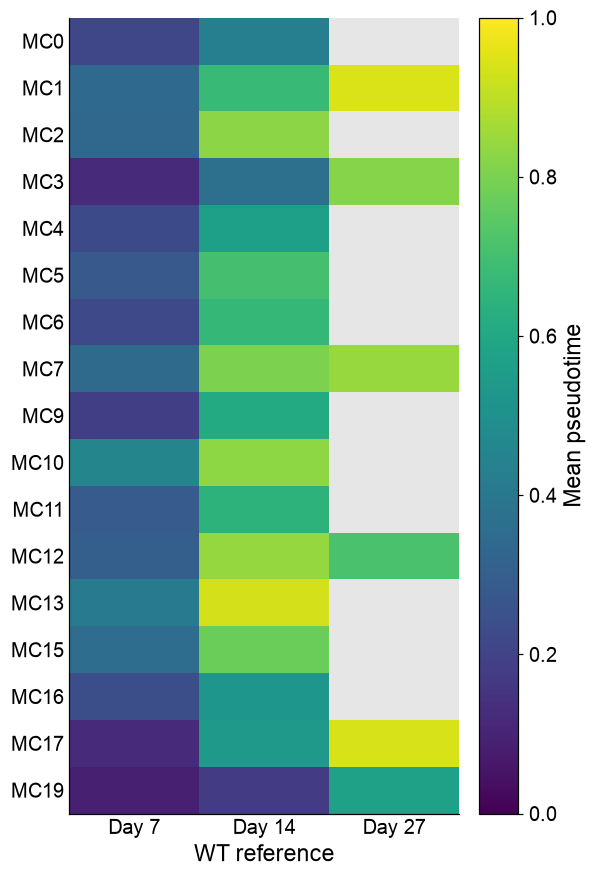

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/panels/figure_5a_wt_reference_position


In [5]:

# WT reference position: equal family means within each observed sample, equal sample mean.
wt=ca.loc[ca.arm=='WT'].groupby(['mc','day','stratum'],observed=True).psi.mean().groupby(['mc','day']).mean().unstack('day').reindex(index=MCS,columns=['D7','D14','D27'])
wt.to_csv(O/'tables/wt_reference_position.csv')
fig,ax=plt.subplots(figsize=(5.6,8.2))
cmap=plt.get_cmap('viridis').copy();cmap.set_bad('#e6e6e6')
im=ax.imshow(wt.values,cmap=cmap,vmin=0,vmax=1,aspect='auto')
ax.set_xticks(range(3),['Day 7','Day 14','Day 27']);ax.set_yticks(range(len(MCS)),['MC'+m for m in MCS]);ax.tick_params(length=0)
ax.set_xlabel('WT reference');cb=fig.colorbar(im,ax=ax,pad=.04);cb.set_label('Mean pseudotime')
fig.tight_layout();stem=O/'panels/figure_5a_wt_reference_position';fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight');plt.show();print(stem)


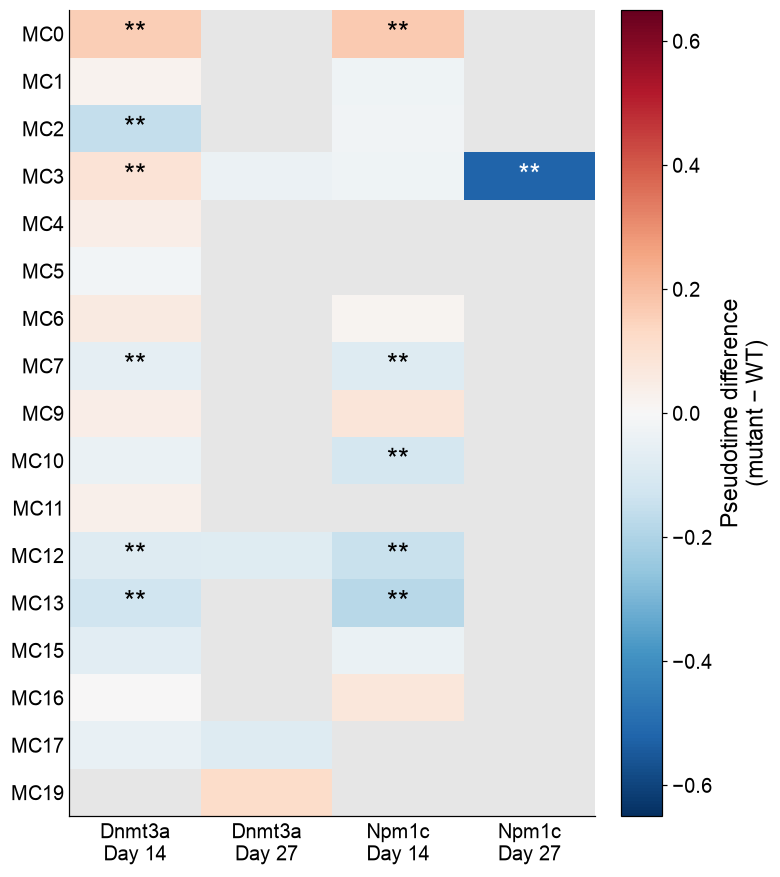

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/panels/figure_5b_state_response


In [6]:

columns=[('Dnmt3a','D14'),('Dnmt3a','D27'),('Npm1c','D14'),('Npm1c','D27')]
matrix=effects.pivot(index='mc',columns=['mutant','day'],values='dpsi').reindex(index=MCS,columns=columns)
qmatrix=effects.pivot(index='mc',columns=['mutant','day'],values='q_state').reindex(index=MCS,columns=columns)
fig,ax=plt.subplots(figsize=(7.3,8.2));cmap=plt.get_cmap('RdBu_r').copy();cmap.set_bad('#e6e6e6')
im=ax.imshow(matrix.values,cmap=cmap,vmin=-.65,vmax=.65,aspect='auto')
for i in range(len(MCS)):
    for j in range(4):
        q=qmatrix.iloc[i,j]
        if pd.notna(q) and q<.1:ax.text(j,i,'**' if q<.05 else '*',ha='center',va='center',fontsize=18,color='white' if abs(matrix.iloc[i,j])>.36 else 'black')
ax.set_xticks(range(4),['Dnmt3a\nDay 14','Dnmt3a\nDay 27','Npm1c\nDay 14','Npm1c\nDay 27']);ax.set_yticks(range(len(MCS)),['MC'+m for m in MCS]);ax.tick_params(length=0)
cb=fig.colorbar(im,ax=ax,pad=.04);cb.set_label('Pseudotime difference\n(mutant − WT)')
fig.tight_layout();stem=O/'panels/figure_5b_state_response';fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight');plt.show();print(stem)


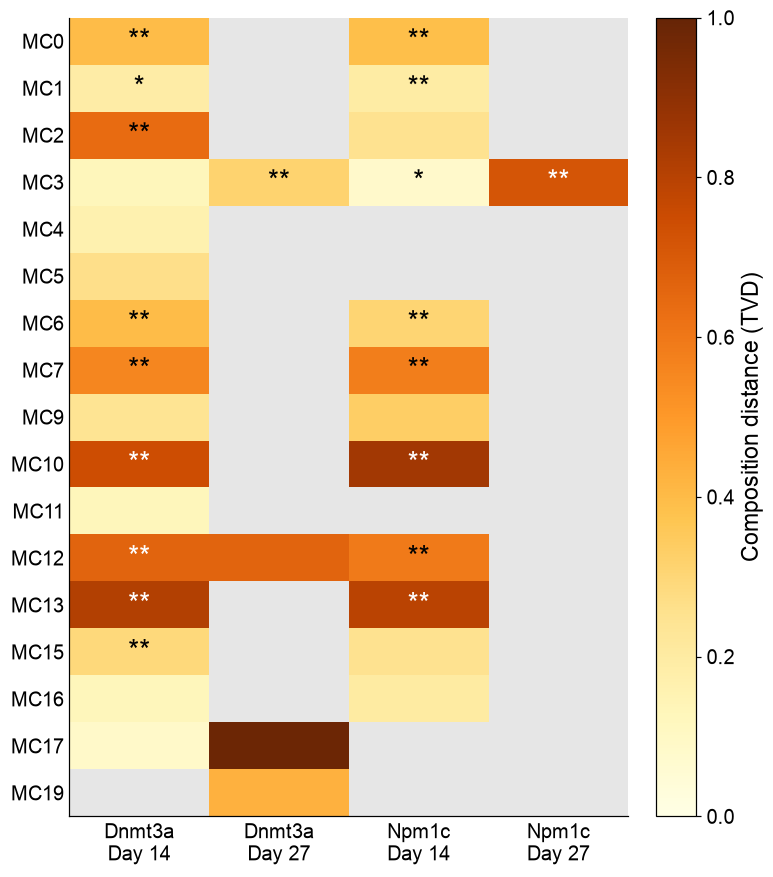

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/panels/figure_5c_composition_response


In [7]:

columns=[('Dnmt3a','D14'),('Dnmt3a','D27'),('Npm1c','D14'),('Npm1c','D27')]
matrix=effects.pivot(index='mc',columns=['mutant','day'],values='tvd').reindex(index=MCS,columns=columns)
qmatrix=effects.pivot(index='mc',columns=['mutant','day'],values='q_composition').reindex(index=MCS,columns=columns)
fig,ax=plt.subplots(figsize=(7.3,8.2));cmap=plt.get_cmap('YlOrBr').copy();cmap.set_bad('#e6e6e6')
im=ax.imshow(matrix.values,cmap=cmap,vmin=0,vmax=1,aspect='auto')
for i in range(len(MCS)):
    for j in range(4):
        q=qmatrix.iloc[i,j]
        if pd.notna(q) and q<.1:ax.text(j,i,'**' if q<.05 else '*',ha='center',va='center',fontsize=18,color='white' if matrix.iloc[i,j]>.65 else 'black')
ax.set_xticks(range(4),['Dnmt3a\nDay 14','Dnmt3a\nDay 27','Npm1c\nDay 14','Npm1c\nDay 27']);ax.set_yticks(range(len(MCS)),['MC'+m for m in MCS]);ax.tick_params(length=0)
cb=fig.colorbar(im,ax=ax,pad=.04);cb.set_label('Composition distance (TVD)')
fig.tight_layout();stem=O/'panels/figure_5c_composition_response';fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight');plt.show();print(stem)


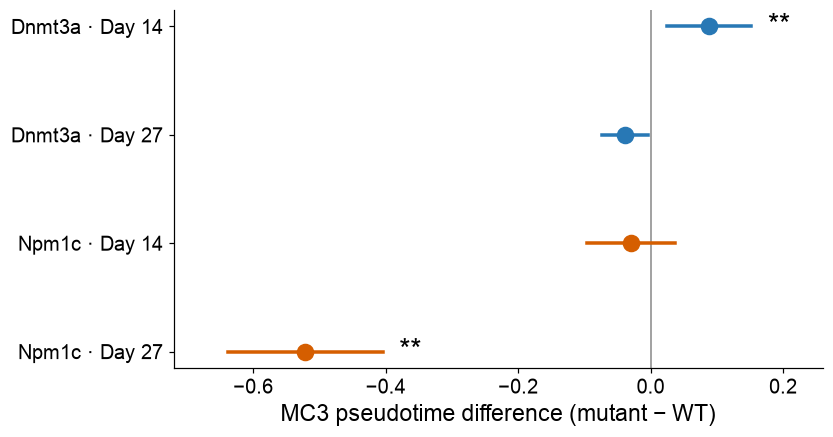

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/panels/figure_5d_mc3_state_contrasts


In [8]:

plot=effects.loc[effects.mc=='3'].sort_values(['mutant','day']).copy().reset_index(drop=True)
fig,ax=plt.subplots(figsize=(7.8,4.2));ax.axvline(0,color='#888888',lw=1)
for i,row in plot.iterrows():
    ax.plot([row.ci_low,row.ci_high],[i,i],color=ARM_COLORS[row.mutant],lw=2.3)
    ax.scatter(row.dpsi,i,s=110,color=ARM_COLORS[row.mutant],zorder=3)
    if pd.notna(row.q_state) and row.q_state<.1:ax.text(row.ci_high+.025,i,'**' if row.q_state<.05 else '*',va='center',fontsize=19)
ax.set_yticks(range(len(plot)),[r.mutant+' · Day '+r.day[1:] for r in plot.itertuples()]);ax.invert_yaxis();ax.set_xlim(-.72,.26);ax.set_xlabel('MC3 pseudotime difference (mutant − WT)')
fig.tight_layout();stem=O/'panels/figure_5d_mc3_state_contrasts';fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight');plt.show();print(stem)


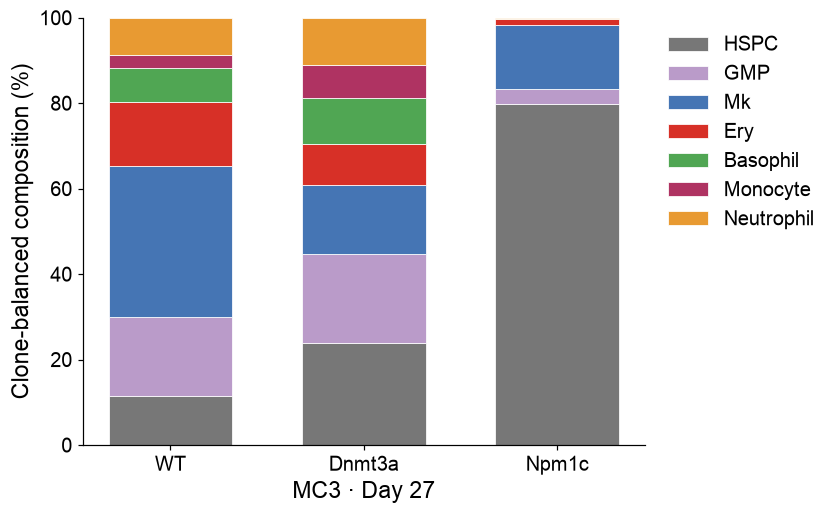

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/panels/figure_5e_mc3_composition


In [9]:

sub=ca.loc[(ca.mc=='3')&(ca.day=='D27')]
composition=sub.groupby(['arm','stratum'],observed=True)[CELLTYPES].mean().groupby('arm').mean().reindex(['WT','Dnmt3a','Npm1c'])
composition.to_csv(O/'tables/mc3_day27_arm_composition.csv')
fig,ax=plt.subplots(figsize=(7.8,4.9));bottom=np.zeros(len(composition))
for ct in CELLTYPES:
    ax.bar(np.arange(len(composition)),composition[ct]*100,bottom=bottom,width=.64,color=CT_COLORS[ct],label=ct,edgecolor='white',linewidth=.5);bottom+=composition[ct].values*100
ax.set_xticks(range(3),['WT','Dnmt3a','Npm1c']);ax.set_ylim(0,100);ax.set_ylabel('Clone-balanced composition (%)');ax.legend(frameon=False,bbox_to_anchor=(1.01,1),loc='upper left',fontsize=13);ax.set_xlabel('MC3 · Day 27')
fig.tight_layout();stem=O/'panels/figure_5e_mc3_composition';fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight');plt.show();print(stem)


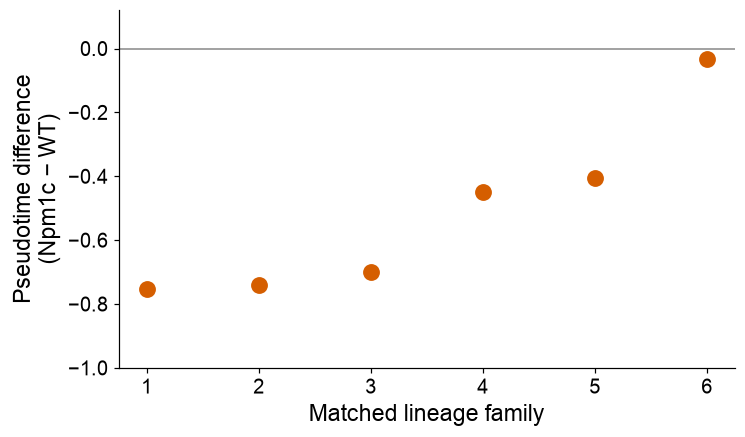

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/panels/figure_s6a_mc3_paired_families


In [10]:

pv=pd.DataFrame(paired_values);sub=pv.loc[(pv.mutant=='Npm1c')&(pv.day=='D27')].sort_values('dpsi')
fig,ax=plt.subplots(figsize=(7,4.2));ax.axhline(0,color='#888888',lw=1)
ax.scatter(np.arange(len(sub)),sub.dpsi,s=100,color=ARM_COLORS['Npm1c']);ax.set_xticks(range(len(sub)),[str(i+1) for i in range(len(sub))]);ax.set_xlabel('Matched lineage family');ax.set_ylabel('Pseudotime difference\n(Npm1c − WT)');ax.set_ylim(-1,.12)
fig.tight_layout();stem=O/'panels/figure_s6a_mc3_paired_families';fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight');plt.show();print(stem)


In [11]:

# Fixed-source provenance and explicit retained versus superseded inference.
paths=[Path(PALANTIR)]+sorted((SRC/'scripts').glob('*.py'))+[SRC/'tables/state_by_metaclone_day.csv']
def sha(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
manifest=[{'path':str(p.relative_to(P)),'bytes':p.stat().st_size,'sha256':sha(p),'role':'immutable input'} for p in paths]
manifest.extend({'path':str(p.relative_to(P)),'bytes':p.stat().st_size,'sha256':sha(p),'role':'generated output'} for folder in ['tables','panels'] for p in sorted((O/folder).glob('*')))
pd.DataFrame(manifest).to_csv(O/'reports/manifest.csv',index=False)
summary={'planned_comparisons':len(effects),'point_estimable':int(effects.point_estimable.sum()),'state_testable':int(effects.p_state.notna().sum()),'composition_testable':int(effects.p_composition.notna().sum()),'state_q_lt_005':int((effects.q_state<.05).sum()),'composition_q_lt_005':int((effects.q_composition<.05).sum()),'old_point_estimates_reproduced':int(audit.dpsi_checkpoint.notna().sum()),'bootstrap_method':'joint lineage-family resampling; fixed sample weights','inference':'conditional family-cluster influence multiplier; not randomized-label or biological-replicate inference','retired':'row-wise arm permutation and independent-arm family bootstrap','old_checkpoint_unchanged':True}
(O/'reports/results_summary.json').write_text(json.dumps(summary,indent=2));display(summary)


{'planned_comparisons': 68,
 'point_estimable': 33,
 'state_testable': 29,
 'composition_testable': 29,
 'state_q_lt_005': 12,
 'composition_q_lt_005': 17,
 'old_point_estimates_reproduced': 33,
 'bootstrap_method': 'joint lineage-family resampling; fixed sample weights',
 'inference': 'conditional family-cluster influence multiplier; not randomized-label or biological-replicate inference',
 'retired': 'row-wise arm permutation and independent-arm family bootstrap',
 'old_checkpoint_unchanged': True}